# Data Loading

In [23]:
import pandas as pd

data = pd.read_csv("predictions.csv", index_col = 0)
data.head()

,split_number,target_organism,curated_smiles,real_pIC50,pred_pIC50
2091,0,Staphylococcus aureus,COc1cc([C@H]2Oc3ccc(C4Oc5cc(O)cc(O)c5C(=O)C4O)...,4.178294,4.122601
1828,0,Staphylococcus aureus,CCOC(=O)Cn1nc(-n2cc(COc3cc(C(F)(F)F)[nH]c(=N)n...,5.134338,4.929649
948,0,Escherichia coli,COC(=O)c1cccc(-c2ccc(O[C@H]3O[C@H](CO)[C@@H](O...,6.050610,6.217894
3160,0,Pseudoalteromonas ulvae,COc1ccc(CCNC(=O)c2cn(-c3cccc(OC)c3)nn2)cc1,4.943095,4.405306
1763,0,Staphylococcus aureus,N=c1[nH]cc(-c2ccc(NC(=O)c3cc4ccccc4[nH]3)cc2)[...,4.045757,4.114314


# Prediction Analysis

## Metrics

In [24]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
def analyze_results(data: pd.DataFrame):
    results = pd.DataFrame(columns=["R2", "MAE", "MSE", "RMSE"])
    for split in sorted(data.split_number.unique()):
        subdata = data[data.split_number.eq(split)]
        y_real = subdata.real_pIC50
        y_pred = subdata.pred_pIC50
        r2=r2_score(y_real, y_pred)
        mae= mean_absolute_error(y_real, y_pred)
        mse=mean_squared_error(y_real, y_pred)
        rmse=mse**0.5
        results.loc[f"Split {split}"] = [r2, mae, mse, rmse]

    results_mean, results_std = results.mean(), results.std()
    results.loc["mean"] = results_mean
    results.loc["std"] = results_std
    return results

analyze_results(data)

,R2,MAE,MSE,RMSE
Split 0,0.467256,0.340847,0.225447,0.474812
Split 1,0.476654,0.393731,0.289060,0.537643
Split 2,0.442686,0.357915,0.246303,0.496289
Split 3,0.366367,0.407757,0.358505,0.598753
Split 4,0.488664,0.341927,0.245152,0.495129
Split 5,0.417615,0.400573,0.308073,0.555044
Split 6,0.492386,0.324313,0.214324,0.462952
Split 7,0.325323,0.382741,0.291494,0.539902
Split 8,0.397093,0.375769,0.312619,0.559123
Split 9,0.461086,0.338835,0.255494,0.505465


# Graph

Text(0, 0.5, 'predicted pIC50')

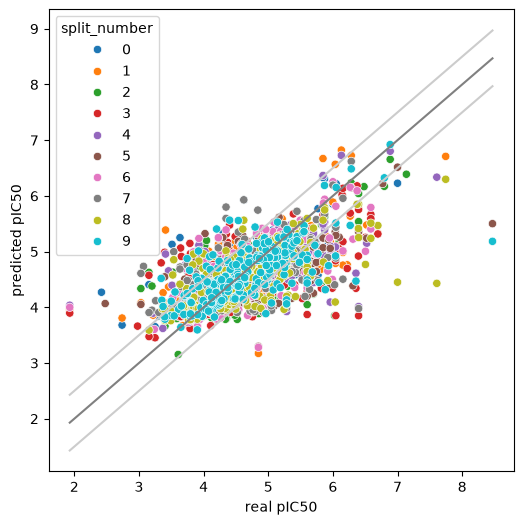

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

xmin = data.real_pIC50.min()
xmax = data.real_pIC50.max()

fig, ax = plt.subplots(figsize=(6,6))
sns.scatterplot(data, x='real_pIC50', y="pred_pIC50", hue="split_number", palette="tab10", legend="full")
sns.lineplot(x = [xmin,xmax], y=[xmin,xmax], color="gray", legend=None)
sns.lineplot(x = [xmin,xmax], y=[xmin-0.5, xmax-0.5], color="0.8", legend=None)
sns.lineplot(x = [xmin,xmax], y=[xmin+0.5, xmax+0.5], color="0.8", legend=None)
plt.xlabel('real pIC50')
plt.ylabel('predicted pIC50')

## RESULTS BY SPECIES

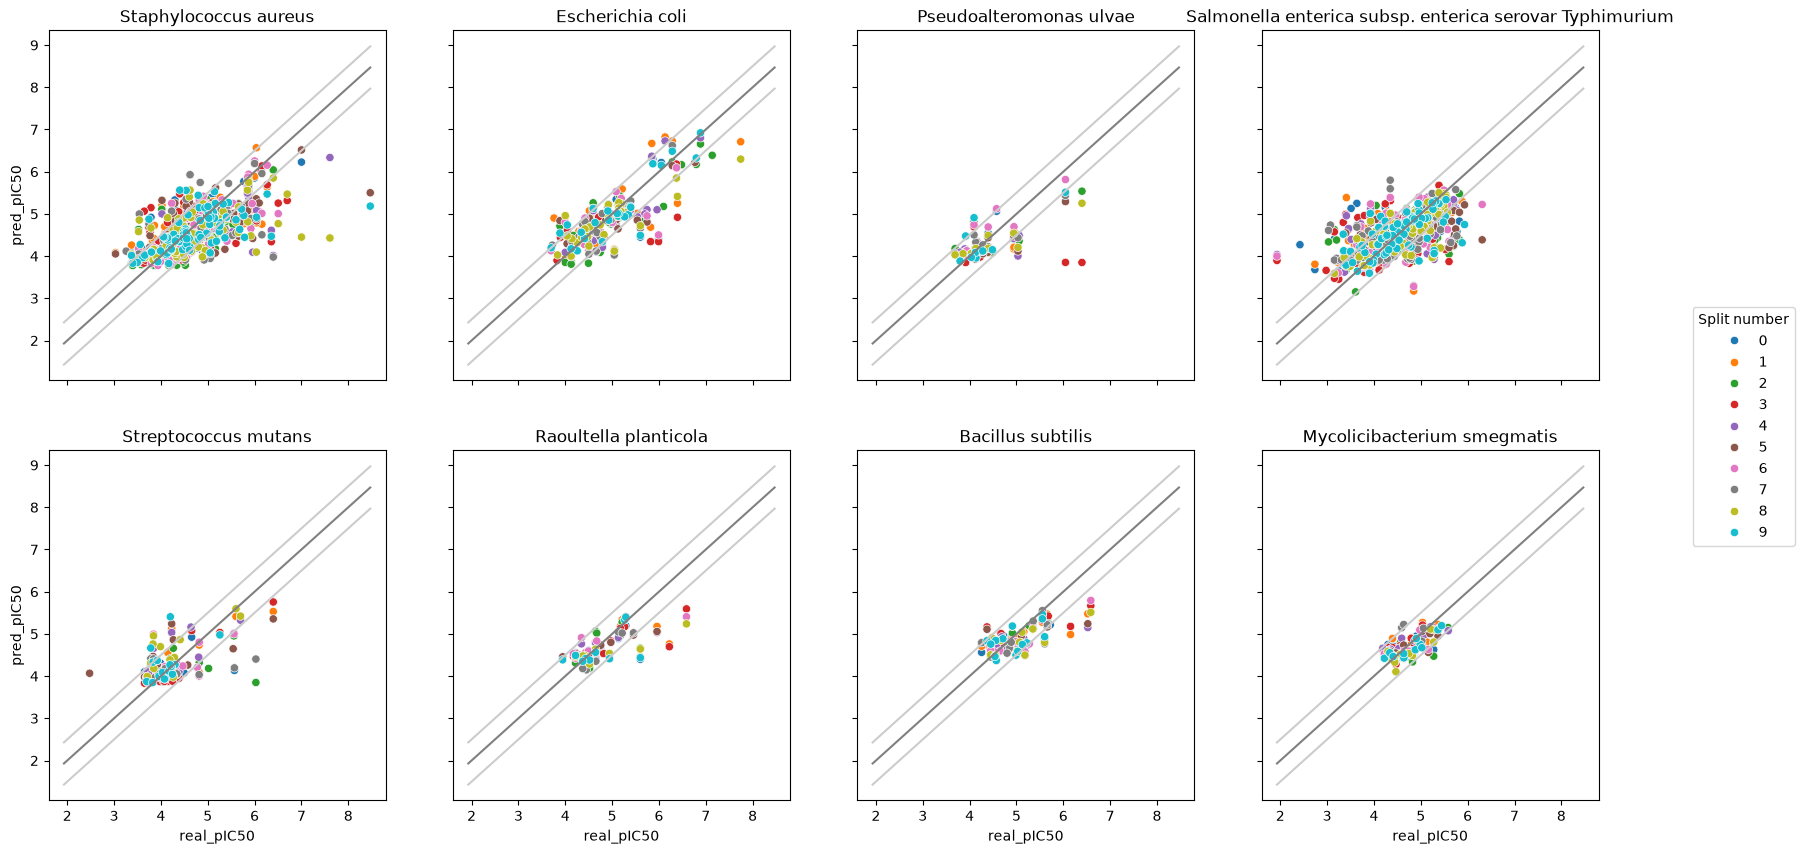

In [26]:
fig, axes = plt.subplots(2, 4, sharex="all", sharey="all", figsize = (20, 10))
for i, specie in enumerate(data.target_organism.unique()):
    ax = axes[i//4][i%4]
    subdata = data[data.target_organism.eq(specie)]
    legend = False if i else "full"
    sns.scatterplot(subdata, x='real_pIC50', y="pred_pIC50", hue="split_number", palette="tab10", legend=legend, ax=ax)
    sns.lineplot(x = [xmin,xmax], y=[xmin,xmax], color="gray", legend=None, ax=ax)
    sns.lineplot(x = [xmin,xmax], y=[xmin-0.5, xmax-0.5], color="0.8", legend=None, ax=ax)
    sns.lineplot(x = [xmin,xmax], y=[xmin+0.5, xmax+0.5], color="0.8", legend=None, ax=ax)
    ax.set_title(specie)
handles, labels = axes[0][0].get_legend_handles_labels()
axes[0][0].get_legend().remove()
fig.legend(handles, labels, loc='center right', title='Split number')

In [27]:
from collections import defaultdict

metrics = defaultdict(dict)

for specie in data.target_organism.unique():
    subdata = data[data.target_organism.eq(specie)]
    results = analyze_results(subdata)
    metrics["R2 mean"][specie] = results.loc["mean", "R2"]
    metrics["R2 std"][specie] = results.loc["std", "R2"]
    metrics["MAE mean"][specie] = results.loc["mean", "MAE"]
    metrics["MAE std"][specie] = results.loc["std", "MAE"]
    metrics["RMSE mean"][specie] = results.loc["mean", "RMSE"]
    metrics["RMSE std"][specie] = results.loc["std", "RMSE"]

metrics = pd.DataFrame(metrics)

metrics.round(3)

,R2 mean,R2 std,MAE mean,MAE std,RMSE mean,RMSE std
Staphylococcus aureus,0.404,0.125,0.388,0.052,0.551,0.088
Escherichia coli,0.546,0.173,0.332,0.052,0.461,0.080
Pseudoalteromonas ulvae,0.314,0.441,0.355,0.123,0.476,0.227
Salmonella enterica subsp. enterica serovar Typhimurium,0.340,0.097,0.400,0.051,0.557,0.060
Streptococcus mutans,0.162,0.374,0.377,0.093,0.519,0.143
Raoultella planticola,0.347,0.164,0.296,0.053,0.452,0.087
Bacillus subtilis,0.401,0.133,0.311,0.048,0.416,0.077
Mycolicibacterium smegmatis,0.333,0.383,0.209,0.028,0.256,0.038


In [28]:
for specie in data.target_organism.unique():
    print(specie)
    subdata = data[data.target_organism.eq(specie)]
    y_real = subdata.real_pIC50
    y_pred = subdata.pred_pIC50
    print("r2_score", r2_score(y_real, y_pred))
    print("MAE", mean_absolute_error(y_real, y_pred))
    print("MSE", mean_squared_error(y_real, y_pred))
    print("RMSE", mean_squared_error(y_real, y_pred)**.5)
    print('..............')

Staphylococcus aureus
r2_score 0.39838545322316055
MAE 0.3877020612561864
MSE 0.3104202120517084
RMSE 0.5571536700513677
..............
Escherichia coli
r2_score 0.5875109211898006
MAE 0.33374296623321764
MSE 0.21881320300792956
RMSE 0.4677747353245251
..............
Pseudoalteromonas ulvae
r2_score 0.3211385921595882
MAE 0.35364451061515007
MSE 0.271556333024685
RMSE 0.5211106725300154
..............
Salmonella enterica subsp. enterica serovar Typhimurium
r2_score 0.3478890710486545
MAE 0.40002707448196706
MSE 0.31353015203764173
RMSE 0.5599376322749184
..............
Streptococcus mutans
r2_score 0.27596295234180557
MAE 0.3692702454010562
MSE 0.2730250899191565
RMSE 0.5225180283197476
..............
Raoultella planticola
r2_score 0.41163229331122153
MAE 0.2956302623219253
MSE 0.21144034923455446
RMSE 0.4598264338144932
..............
Bacillus subtilis
r2_score 0.4234841537481491
MAE 0.31060428410774876
MSE 0.17712636780373248
RMSE 0.4208638352290827
..............
Mycolicibacterium s